# Creditworthiness Modelling: Logistic Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import optuna
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, roc_auc_score, f1_score, 
                            classification_report, confusion_matrix, 
                            ConfusionMatrixDisplay)

c:\Users\anhdl\CodeAlpha\CodeAlpha_Creditworthiness\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## <font color="orange"> Load the data and split </font>

In [ ]:
# load data
path = "../data/processed-data/processed_data.csv"
df = pd.read_csv(path)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32574 entries, 0 to 32573
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   person_age_years                  32574 non-null  int64  
 1   person_home_ownership             32574 non-null  str    
 2   person_emp_length_years           31679 non-null  float64
 3   loan_intent                       32574 non-null  str    
 4   loan_grade                        32574 non-null  str    
 5   loan_int_rate                     29459 non-null  float64
 6   loan_status                       32574 non-null  int64  
 7   cb_person_default_on_file         32574 non-null  int64  
 8   cb_person_cred_hist_length_years  32574 non-null  int64  
 9   loan_term_months                  32574 non-null  int64  
 10  loan_to_income_ratio              32574 non-null  float64
 11  open_accounts                     32574 non-null  int64  
 12  credit_utilizat

In [4]:
# X/y split
y = df.pop("loan_status")
X = df.copy()

In [5]:
# train-test stratified split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## <font color="orange">Logistic Regression </font>

In [6]:
# feature division 
binary_features = ["high_lti", "loan_grade_sep", "high_income", "high_lti_x_rent", "cb_person_default_on_file"]
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
numeric_features = [ft for ft in numeric_features if ft not in binary_features]
ohe_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [7]:
# optuna study + cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
def optuna_study(metric: str, ntrials: int=120): 
    def objective(trial):
        """ Objective function """
        # hyperparams for preprocessor:
        ## scaler
        scaler_ind = trial.suggest_categorical("scaler_ind",["standard", "robust"])
        if scaler_ind == "standard":
            scaler = StandardScaler()
        else:
            scaler = RobustScaler()
        ## kNN 
        knn_n_neighbors = trial.suggest_int("knn_n_neighbors", 2, 40)
        knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])

        # hyperparams for log-reg
        ib_ratio = (y_train==0).sum() / (y_train==1).sum()
        pos_weight = trial.suggest_float("pos_weight", 1.0, 2 * ib_ratio)
        logit_C = trial.suggest_float('logit_C', 1e-4, 1e2, log=True)
        logit_solver = trial.suggest_categorical('logit_solver', ["lbfgs", "newton-cholesky", "liblinear", "saga"])
        if logit_solver in ["lbfgs", "newton-cholesky"]:
            logit_l1_ratio = 0
        elif logit_solver == "liblinear":
            logit_l1_ratio = trial.suggest_categorical("logit_l1_ratio", [0.0, 1.0])
        else:
            logit_l1_ratio = trial.suggest_float("l1_ratio", 0.0, 1.0)

        # processor pipeline
        preprocessor = ColumnTransformer(
            transformers=[
                ("numeric", Pipeline([
                    ("scaler", scaler),
                    ("imputer", KNNImputer(n_neighbors=knn_n_neighbors, weights= knn_weights, add_indicator=True)), 
                ]), numeric_features),
                ("ohe", Pipeline([
                    ("encoder", OneHotEncoder(handle_unknown="ignore")),
                ]), ohe_features),
            ],
            remainder="passthrough",
        )
        # Logistic regression pipeline
        logreg_pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(C=logit_C, 
                                        solver=logit_solver, 
                                        l1_ratio=logit_l1_ratio,
                                        class_weight={0: 1.0, 1: pos_weight}, 
                                        max_iter = 2000,
                                        random_state=42)
            ),
        ])

        if metric=="f1":
            # tuned threshold instead of using default 0.5
            threshold = trial.suggest_float("threshold", 0.15, 0.75)
            def f1_at_threshold(estimator, X, y):
                proba = estimator.predict_proba(X)[:, 1]
                return f1_score(y, (proba >= threshold).astype(int))
        
            scores = cross_val_score(logreg_pipeline, X_train, y_train, scoring=f1_at_threshold, cv=cv, n_jobs=-1)
        else:
            scores = cross_val_score(logreg_pipeline, X_train, y_train, scoring=metric, cv=cv, n_jobs=-1)
        return scores.mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=ntrials)

    return study

In [8]:
def retrain_and_evaluation(study, metric):
    best_params = study.best_params

    scaler_map = {
        "standard": StandardScaler,
        "robust": RobustScaler,
    }
    best_scaler = scaler_map[best_params["scaler_ind"]]()

    best_l1_ratio = best_params.get(
        "logit_l1_ratio",
        best_params.get("logit_l1_ratio", 0.0),
    )

    best_preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", Pipeline([
                ("scaler", best_scaler),
                ("imputer", KNNImputer(
                    n_neighbors=best_params["knn_n_neighbors"],
                    weights=best_params["knn_weights"],
                    add_indicator=True,
                )),
            ]), numeric_features),
            ("ohe", Pipeline([
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]), ohe_features),
        ],
        remainder="passthrough",
    )

    best_pipeline = Pipeline([
        ("preprocessor", best_preprocessor),
        ("classifier", LogisticRegression(
            C=best_params["logit_C"],
            solver=best_params["logit_solver"],
            l1_ratio=best_l1_ratio,
            class_weight={0: 1.0, 1: best_params["pos_weight"]},
            max_iter=2000,
            random_state=42,
        )),
    ])

    best_pipeline.fit(X_train, y_train)
    y_prob = best_pipeline.predict_proba(X_test)[:, 1]
    threshold = best_params.get("threshold", 0.5)
    y_pred = (y_prob >= threshold).astype(int)

    print(f"Best CV {metric.upper()}:             {study.best_value:.4f}")
    print(f"Test F1:                {f1_score(y_test, y_pred):.4f}")
    print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
    print(f"Test ROC-AUC:           {roc_auc_score(y_test, y_prob):.4f}")
    print(f"Test average precision: {average_precision_score(y_test, y_prob):.4f}")
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0, digits=3))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.show()

    # Training-set metrics for the best-performing pipeline
    y_train_prob = best_pipeline.predict_proba(X_train)[:, 1]
    y_train_pred = (y_train_prob >= threshold).astype(int)   # tuned threshold

    print(f"Training F1:                {f1_score(y_train, y_train_pred):.4f}")
    print(f"Training balanced accuracy: {balanced_accuracy_score(y_train, y_train_pred):.4f}")
    print(f"Training ROC-AUC:           {roc_auc_score(y_train, y_train_prob):.4f}")
    print(f"Training average precision: {average_precision_score(y_train, y_train_prob):.4f}")

    print("\nTraining classification report:")
    print(classification_report(y_train, y_train_pred, zero_division=0, digits=3))

    ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
    plt.show()

    return best_pipeline

In [9]:
# study to optimize f1 score
f1_study = optuna_study(metric="f1")

print("Best performing pipeline: ")
print(f1_study.best_trial)

print("Best params:")
print(f1_study.best_value, f1_study.best_params)



[I 2026-11-12 23:54:19,517] A new study created in memory with name: no-name-f0988767-6e05-41a4-a6ef-7e5d77b79d90
[I 2026-11-12 23:54:35,941] Trial 0 finished with value: 0.12629480699207715 and parameters: {'scaler_ind': 'robust', 'knn_n_neighbors': 30, 'knn_weights': 'uniform', 'pos_weight': 1.9618656143136237, 'logit_C': 0.00022310108018679258, 'logit_solver': 'lbfgs', 'threshold': 0.7319459112971965}. Best is trial 0 with value: 0.12629480699207715.
[I 2026-11-12 23:54:48,071] Trial 1 finished with value: 0.6474247452559316 and parameters: {'scaler_ind': 'standard', 'knn_n_neighbors': 9, 'knn_weights': 'distance', 'pos_weight': 4.23565960130606, 'logit_C': 0.039054412752107935, 'logit_solver': 'newton-cholesky', 'threshold': 0.369817105976215}. Best is trial 1 with value: 0.6474247452559316.
[I 2026-11-12 23:55:08,401] Trial 2 finished with value: 0.7451895078213852 and parameters: {'scaler_ind': 'robust', 'knn_n_neighbors': 9, 'knn_weights': 'distance', 'pos_weight': 1.28641425781

Best performing pipeline: 
FrozenTrial(number=96, state=<TrialState.COMPLETE: 1>, values=[0.7528162636156108], datetime_start=datetime.datetime(2026, 11, 13, 0, 12, 11, 276485), datetime_complete=datetime.datetime(2026, 11, 13, 0, 12, 24, 870131), params={'scaler_ind': 'robust', 'knn_n_neighbors': 36, 'knn_weights': 'distance', 'pos_weight': 1.1477688931235397, 'logit_C': 8.292797563627865, 'logit_solver': 'newton-cholesky', 'threshold': 0.40023959693386196}, user_attrs={}, system_attrs={'tpe:relative_params:0': '{"knn_n_neighbors": 36, "knn_weights": "distance", "logit_C": 8.292797563627865, "logit_solver": "newton-cholesky", "pos_weight": 1.1477688931235397, "scaler_ind": "robust", "threshold": 0.40023959693386196}'}, intermediate_values={}, distributions={'scaler_ind': CategoricalDistribution(choices=('standard', 'robust')), 'knn_n_neighbors': IntDistribution(high=40, log=False, low=2, step=1), 'knn_weights': CategoricalDistribution(choices=('uniform', 'distance')), 'pos_weight': Fl

Best CV F1:             0.7528
Test F1:                0.7404
Test balanced accuracy: 0.8238
Test ROC-AUC:           0.9040
Test average precision: 0.8160

Classification report:
              precision    recall  f1-score   support

           0      0.919     0.946     0.932      5094
           1      0.784     0.702     0.740      1421

    accuracy                          0.893      6515
   macro avg      0.851     0.824     0.836      6515
weighted avg      0.890     0.893     0.891      6515



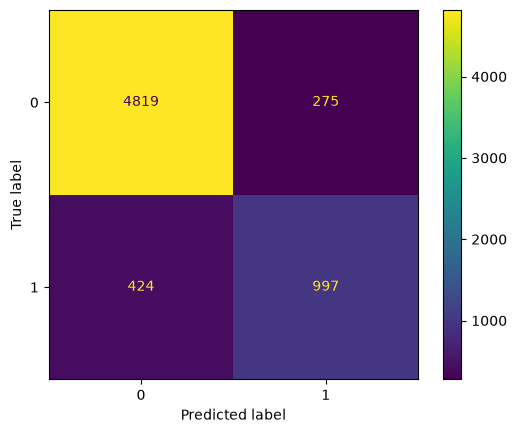

Training F1:                0.7532
Training balanced accuracy: 0.8347
Training ROC-AUC:           0.9134
Training average precision: 0.8303

Training classification report:
              precision    recall  f1-score   support

           0      0.925     0.944     0.934     20373
           1      0.783     0.725     0.753      5686

    accuracy                          0.896     26059
   macro avg      0.854     0.835     0.844     26059
weighted avg      0.894     0.896     0.895     26059



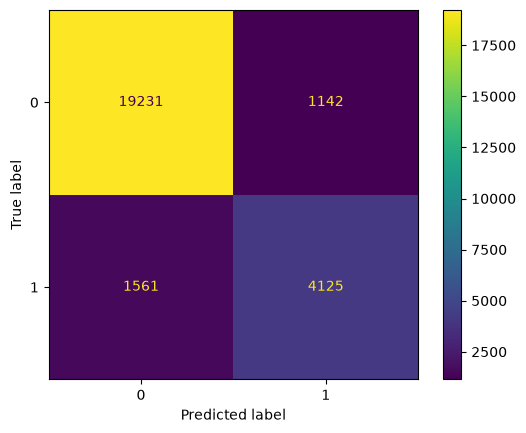

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['person_age_years','person_home_ownership','person_emp_length_years',..., 'high_lti_x_rent','log_person_income_usd','log_loan_amount_usd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dro

In [10]:
# evaluation
best_f1_pipeline = retrain_and_evaluation(f1_study, metric="f1")
best_f1_pipeline